# 8.1 — Simple Linear Regression

**Chapter 8, section 8.2.1.**

**The question this notebook answers:** does a gradient descent loop written on an RDD arrive at
the same answer as the closed-form solution?

One parameter, one thousand points, and four routes to the slope of the line through them:
scikit-learn, the normal equations in NumPy, gradient descent in NumPy, and the same gradient
descent as a `map` and a `reduce` over a Spark RDD. The four are worth doing together because the
first two give an exact answer to compare the last two against. Everything that follows in this
chapter — many parameters, a different loss, class weights, a penalty — is a variation on the
loop written at the end of this notebook.

Source: `Notebooks old/Spark-Example-17-Simple-Linear-Regression-Implementation.ipynb`.

In [1]:
# --- CS-777 session setup ------------------------------------------------
import os, tempfile
import numpy as np
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession

SCRATCH = os.environ.get("CS777_SCRATCH", os.path.join(tempfile.gettempdir(), "cs777"))
os.makedirs(SCRATCH, exist_ok=True)

spark = (SparkSession.builder
         .appName("CS777-8.1")
         .master("local[4]")
         .config("spark.ui.showConsoleProgress", "false")
         .config("spark.sql.warehouse.dir", os.path.join(SCRATCH, "warehouse"))
         .getOrCreate())
sc = spark.sparkContext
sc.setLogLevel("ERROR")

print("Spark", spark.version)

Spark 4.2.0


---

## 1. The model

Linear regression with a slope and no intercept — *simple* linear regression — models the
relationship between one predictor and one response as a straight line through the origin:

$$y = \beta x + \epsilon$$

where $y$ is the response, $x$ the predictor, $\beta$ the slope, and $\epsilon$ the noise. The
task is to estimate $\beta$ from a set of paired observations.

The data below is generated from a known slope of $2.5$ with Gaussian noise added. The noise has
mean $50$, not zero, which matters: the estimate will come out slightly above $2.5$ and that is
the noise showing through, not an error in the fit.

The generator is **seeded**, so every number printed in this notebook is reproducible.

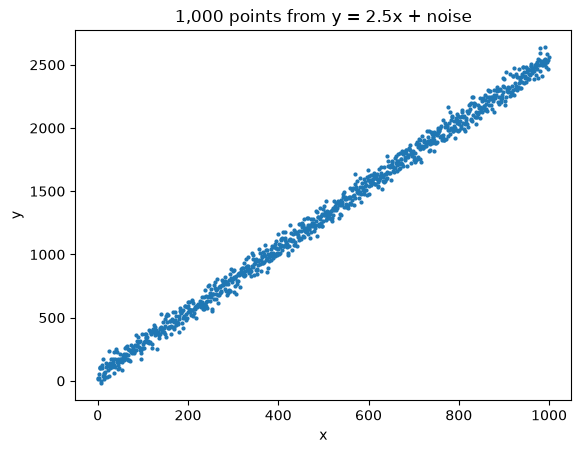

In [2]:
np.random.seed(777)

size = 1000
mu, sigma = 50, 50                       # mean and standard deviation of the noise
error = np.random.normal(mu, sigma, size)
x1 = np.arange(0, size)
y = 2.5 * x1 + error

plt.plot(x1, y, 'o', markersize=2)
plt.xlabel("x"); plt.ylabel("y"); plt.title("1,000 points from y = 2.5x + noise")
plt.show()

In [3]:
myRDD = sc.parallelize(list(zip(y, x1)))
myRDD.take(5)

[(np.float64(26.589560304072336), np.int64(0)),
 (np.float64(11.358757298848168), np.int64(1)),
 (np.float64(51.73099489221156), np.int64(2)),
 (np.float64(21.831903790109607), np.int64(3)),
 (np.float64(105.3175443664083), np.int64(4))]

---

## 2. The slope from scikit-learn

`fit()` returns a fitted `LinearRegression` whose `coef_` attribute holds the slope.
`fit_intercept=False` is what makes this the no-intercept model above.

In [4]:
from sklearn.linear_model import LinearRegression

X = np.stack([x1], axis=1)
reg = LinearRegression(fit_intercept=False).fit(X, y)
print(reg.coef_)

[2.57785458]


---

## 3. The same slope as linear algebra

The normal equations give the coefficients of a linear model in closed form:

$$
\hat{\beta} = (X^T X)^{-1} X^T y
$$

where $X$ is the matrix of predictors and $y$ the vector of responses. This is the expression
`LinearRegression` evaluates internally, so the two answers should agree to within floating-point
noise — and the notebook checks that rather than asserting it.

In [5]:
beta_hat = np.linalg.inv(X.T.dot(X)).dot(X.T).dot(y)
print(beta_hat)

assert np.allclose(reg.coef_, beta_hat), "scikit-learn and the normal equations disagree"
print("scikit-learn and the normal equations agree")

[2.57785458]
scikit-learn and the normal equations agree


---

## 4. The same slope by gradient descent

Gradient descent finds the minimum of a function by repeatedly stepping in the direction of the
negative gradient. For this model:

1. **Predict** with the current coefficient: $y_{\text{prediction}} = m\,x$.

2. **Cost**, computed only so the run can be monitored:
   $\text{cost} = \frac{1}{n}\sum (y - y_{\text{prediction}})^2$

3. **Gradient**, differentiated term by term:

$$
\begin{align*}
m_{\text{gradient}} & = \frac{\partial }{\partial m} \left(\frac{1}{2n} \sum (y - mx)^2 \right) \\
& = \frac{1}{2n}\sum \frac{\partial }{\partial m} (y - mx)^2 \\
& = \frac{1}{2n}\sum 2(y - mx)(-x) \\
& = \frac{-1}{n} \sum x(y - mx)
\end{align*}
$$

4. **Update**: $m \leftarrow m - \text{learningRate} \times m_{\text{gradient}}$

Here $n$ is the number of observations. Note that the gradient is a **sum over independent
per-example contributions** — each term needs one observation and the current coefficient, and
nothing else. That is the property the distributed version depends on.

In [6]:
# Gradient descent with plain NumPy, on data that fits in one process.
learningRate = 0.000002
num_iteration = 10
m_current = 0
n = float(size)

for i in range(num_iteration):
    y_prediction = m_current * x1
    cost = sum((y - y_prediction) ** 2) / size          # monitoring only
    m_gradient = (-1 / n) * sum(x1 * (y - y_prediction))
    print(i, "m=", m_current, " Cost=", cost)
    m_current = m_current - learningRate * m_gradient

m_numpy = m_current
print("\nNumPy gradient descent:", m_numpy)

0 m= 0  Cost= 2214953.5475185956
1 m= 1.7159927228478782  Cost= 250394.3728667534
2 m= 2.289705717855777  Cost= 30798.78733024408
3 m= 2.481516904615753  Cost= 6252.710118969309
4 m= 2.545645714118776  Cost= 3508.985080099212
5 m= 2.5670860913863502  Cost= 3202.2954602415475
6 m= 2.57425431703935  Cost= 3168.014137734402
7 m= 2.576650891426594  Cost= 3164.182221044873
8 m= 2.577452145331205  Cost= 3163.753894934862
9 m= 2.577720030952895  Cost= 3163.706017261261

NumPy gradient descent: 2.577809593956452


---

## 5. The same loop on an RDD

Now the same arithmetic, with the sum computed across the partitions of an RDD instead of by a
Python loop.

* `myRDD` holds tuples $(y, x)$ — the response is `x[0]` and the predictor is `x[1]`.
* `m` is the current coefficient. It lives **on the driver**, and Spark serializes a copy of it
  into every task at the start of each iteration.
* The `map` computes each example's contribution to the gradient and to the cost; the `reduce`
  adds those contributions up.

$$m_{\text{gradient}} = \frac{-1}{n} \sum (x \cdot (y - mx)) \qquad
  \text{cost} = \frac{1}{2n} \sum (y - mx)^2$$

`cache()` is not an optimization here but a requirement: the loop traverses the same RDD on every
iteration, and an uncached RDD would be rebuilt from its source each time.

In [7]:
learningRate = 0.000002
num_iteration = 10

m = 0
myRDD.cache()

for i in range(num_iteration):
    gradientCost = myRDD.map(lambda x: (x[1] * (x[0] - x[1] * m), (x[0] - x[1] * m)**2))\
                        .reduce(lambda x, y: (x[0] + y[0], x[1] + y[1]))
    cost = gradientCost[1] / (2 * size)
    gradient = (-1.0 / float(size)) * gradientCost[0]
    print(i, "m", m, " Cost", cost)
    m = m - learningRate * gradient

m_spark = m
print("\nSpark gradient descent:", m_spark)

0 m 0  Cost 1107476.7737592994


1 m 1.7159927228478775  Cost 125197.18643337688
2 m 2.2897057178557767  Cost 15399.393665122088
3 m 2.4815169046157526  Cost 3126.3550594846724
4 m 2.5456457141187756  Cost 1754.4925400496115
5 m 2.56708609138635  Cost 1601.1477301207763
6 m 2.5742543170393497  Cost 1584.0070688672029
7 m 2.576650891426594  Cost 1582.0911105224363
8 m 2.577452145331205  Cost 1581.87694746743
9 m 2.577720030952895  Cost 1581.8530086306307

Spark gradient descent: 2.577809593956452


---

## 6. One arithmetic operation less per example

The version above evaluates the residual $t = y - mx$ **twice** for every example: once inside the
gradient term and once inside the squared error. Since both need the same quantity, it can be
computed once in a first `map` and consumed by a second:

$$m_{\text{gradient}} = \frac{-1}{n} \sum (x \cdot t) \qquad \text{cost} = \frac{1}{2n} \sum t^2$$

Both `map`s are narrow transformations, so Spark pipelines them into a single stage and nothing is
materialized in between. One arithmetic operation per example is not worth much here; the same
elimination applied to the exponential in logistic regression is, and that is where this pattern
is going.

Note the cost printed below is **half** the cost printed above: this version divides the
accumulated squared error by $n$ where the previous one divided by $2n$. The objective value is
only ever used for monitoring and never enters the update, so a constant factor changes what is
printed and nothing else.

In [8]:
learningRate = 0.000002
num_iteration = 10

m = 0
myRDD.cache()

for i in range(num_iteration):
    gradientCost = myRDD.map(lambda x: (x[1], (x[0] - x[1] * m)))\
                        .map(lambda x: (x[0] * x[1], x[1]**2))\
                        .reduce(lambda x, y: (x[0] + y[0], x[1] + y[1]))
    cost = gradientCost[1] / size
    gradient = (-1.0 / float(size)) * gradientCost[0]
    print(i, "m", m, " Cost", cost)
    m = m - learningRate * gradient

m_spark_opt = m
print("\nSpark gradient descent, residual reused:", m_spark_opt)

0 m 0  Cost 2214953.547518599


1 m 1.7159927228478775  Cost 250394.37286675375
2 m 2.2897057178557767  Cost 30798.787330244177


3 m 2.4815169046157526  Cost 6252.710118969345
4 m 2.5456457141187756  Cost 3508.985080099223
5 m 2.56708609138635  Cost 3202.2954602415525
6 m 2.5742543170393497  Cost 3168.0141377344057
7 m 2.576650891426594  Cost 3164.1822210448727
8 m 2.577452145331205  Cost 3163.75389493486
9 m 2.577720030952895  Cost 3163.7060172612614

Spark gradient descent, residual reused: 2.577809593956452


---

## 7. Do the four routes agree?

Two of the four are exact and two are iterative, so they should agree to the precision gradient
descent has reached after ten iterations rather than exactly.

In [9]:
print(f"scikit-learn          {reg.coef_[0]:.8f}")
print(f"normal equations      {beta_hat[0]:.8f}")
print(f"gradient descent      {m_numpy:.8f}")
print(f"  ... on an RDD       {m_spark:.8f}")
print(f"  ... residual reused {m_spark_opt:.8f}")

assert np.isclose(m_spark, m_spark_opt), "the two RDD loops must agree exactly"
assert abs(m_spark - beta_hat[0]) < 1e-3, "gradient descent has not reached the exact solution"
print("\nAll four routes agree to within 1e-3.")

scikit-learn          2.57785458
normal equations      2.57785458
gradient descent      2.57780959
  ... on an RDD       2.57780959
  ... residual reused 2.57780959

All four routes agree to within 1e-3.


---

## Conclusion

The exact solution and the iterative one arrive at the same slope, and the RDD version of the
iterative one arrives there by exactly the arithmetic the NumPy version uses. The only thing that
changed between section 4 and section 5 is **where the summation happens**: a Python `for` loop
became a `map` and a `reduce`, and the parameter update stayed on the driver.

That division — per-example work distributed, aggregation distributed, update on the driver — is
the shape of every training loop in this chapter. What changes from here on is the number of
parameters (8.2), the loss function (8.4), the weighting of the examples (8.5), and the penalty
added to the objective (8.6). The structure does not change.